In [1]:
from astropy.io import fits
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from GalVel_Pop import gal_population, UVW

Reading the APOGEE DR17 data 

In [2]:
from astropy.table import Table
dat = Table.read('allStar-dr17-synspec_rev1.fits', format='fits')
names = [name for name in dat.colnames if len(dat[name].shape) <= 1]
allstar = dat[names].to_pandas()

FileNotFoundError: [Errno 2] No such file or directory: 'allStar-dr17-synspec_rev1.fits'

and adding the distances from Bailer Jones

In [ ]:
#BJ distances
pd.set_option('display.max_seq_items', 500)
# Read the data
BJ_distances_hdus = fits.open('apogee_BJ_distances.fits')
BJ_distances = pd.DataFrame(BJ_distances_hdus[1].data)
BJ_distances_hdus.close()


print ((BJ_distances.columns))


Index(['source_id', 'r_med_geo', 'r_lo_geo', 'r_hi_geo', 'r_med_photogeo',
       'r_lo_photogeo', 'r_hi_photogeo', 'flag', 'apogaia_dr3_ids_oid',
       'gaiaedr3_source_id'],
      dtype='object')


In [ ]:
#apogee_BJdistances= allstar.merge(BJ_distances, left_on = 'GAIAEDR3_SOURCE_ID', right_on = 'gaiaedr3_source_id')
#print (len(apogee_BJdistances))

### Excluding bad measurements based on some flags

In [ ]:
print (f' Full sample contains {len(allstar)} stars')
#APOGEE_STARFLAG
# PERSIST_HIGH	(bit = 9)	Spectrum has significant number (>20%) of pixels in high persistence region: WARN
allstar = allstar[allstar['STARFLAG'] != 2**9]
# LOW_SNR	(bit = 4)	Spectrum has low S/N (S/N<5)
allstar = allstar[allstar['STARFLAG'] != 2**4]
#VERY_BRIGHT_NEIGHBOR	(bit = 3)	Star has neighbor more than 100 times brighter: possibly BAD
allstar = allstar[allstar['STARFLAG'] != 2**3]
#PERSIST_JUMP_POS	(bit = 12)	Spectrum show obvious positive jump in blue chip: WARN
allstar = allstar[allstar['STARFLAG'] != 2**12]
#PERSIST_JUMP_NEG	(bit = 13)	Spectrum show obvious negative jump in blue chip: WARN
allstar = allstar[allstar['STARFLAG'] != 2**13]
#SUSPECT_RV_COMBINATION	(bit = 16)	RVs from synthetic template differ significantly (~2 km/s) from those from combined template: WARN
allstar = allstar[allstar['STARFLAG'] != 2**16]


#APOGEE_EXTRATARG
# Select stars from the Main Survey Targets: no information in the bitmaks
MST_sample = allstar[allstar['EXTRATARG'] == 0]
print (f' MST sample contains {len(MST_sample)} stars')

 Full sample contains 733901 stars
 MST sample contains 351883 stars


### Further selection

https://www.sdss4.org/dr17/irspec/abundances/

cool (Teff < 3500) and hot (Teff > 6000) stars are not good.
SNR > 100 should be considered

In [ ]:
criteria = (MST_sample['TEFF'] > 4000) & (MST_sample['TEFF'] < 6000) & (MST_sample['SNR'] > 100)
MST_sample = MST_sample[criteria]
print (f' MST sample with good spectra and not too coold/hot: {len(MST_sample)} stars')

 MST sample with good spectra and not too coold/hot: 221177 stars


In [ ]:

def calculate_X_H(df, element):
    # Create column names dynamically
    X_FE_col = f'{element}_FE'
    X_FE_err_col = f'{element}_FE_ERR'
    FE_H_col = 'FE_H'
    FE_H_err_col = 'FE_H_ERR'
    
    # Compute X_H
    df[f'{element}_H'] = df[X_FE_col] + df[FE_H_col]
    
    # Propagate the uncertainties
    df[f'{element}_H_ERR'] = np.sqrt(df[X_FE_err_col]**2 + df[FE_H_err_col]**2)
    
    return df

MST_sample = calculate_X_H(MST_sample, 'CI')
MST_sample = calculate_X_H(MST_sample, 'O')
MST_sample = calculate_X_H(MST_sample, 'MG')
MST_sample = calculate_X_H(MST_sample, 'SI')

In [ ]:
abundance_criteria = (
    (MST_sample['FE_H_FLAG'] == 0) &
    (MST_sample['FE_H'] > -1) & 
    (MST_sample['FE_H'] < 0.6) & 
    (MST_sample['FE_H_ERR'] < 0.05) &
    (MST_sample['C_FE_FLAG'] == 0) &
    (MST_sample['C_H'] > -1) & 
    (MST_sample['C_H'] < 0.6) &
    (MST_sample['C_H_ERR'] < 0.05) &
    (MST_sample['O_FE_FLAG'] == 0) &
    (MST_sample['O_H'] > -1) & 
    (MST_sample['O_H'] < 0.6) &
    (MST_sample['O_H_ERR'] < 0.05) &
    (MST_sample['MG_FE_FLAG'] == 0) &
    (MST_sample['MG_H'] > -1) & 
    (MST_sample['MG_H'] < 0.6) &
    (MST_sample['MG_H_ERR'] < 0.05) &
    (MST_sample['SI_FE_FLAG'] == 0) &
    (MST_sample['SI_H'] > -1) & 
    (MST_sample['SI_H'] < 0.6) &
    (MST_sample['SI_H_ERR'] < 0.05)
)
MST_sample = MST_sample[abundance_criteria]
print (f' MST sample with good spectra and not too coold/hot: {len(MST_sample)} stars')

 MST sample with good spectra and not too coold/hot: 185322 stars


In [ ]:
kinematic_criteria = (
    (MST_sample['GAIAEDR3_PARALLAX'] == MST_sample['GAIAEDR3_PARALLAX']) &
    (MST_sample['GAIAEDR3_PMRA'] == MST_sample['GAIAEDR3_PMRA']) &
    (MST_sample['GAIAEDR3_PMDEC'] == MST_sample['GAIAEDR3_PMDEC']) &
    (MST_sample['VHELIO_AVG'] == MST_sample['VHELIO_AVG'])
)

MST_sample = MST_sample[kinematic_criteria]
print (f' MST sample with good kinematics: {len(MST_sample)} stars')

 MST sample with good kinematics: 184282 stars


In [ ]:
relevant_columns = [ 'RA', 'DEC', 'GLON', 'GLAT',
       'SNR', 
       'VHELIO_AVG', 'VERR', 
       'GAIAEDR3_SOURCE_ID',
       'GAIAEDR3_PARALLAX', 'GAIAEDR3_PARALLAX_ERROR', 
       'GAIAEDR3_PMRA', 'GAIAEDR3_PMRA_ERROR', 
       'GAIAEDR3_PMDEC', 'GAIAEDR3_PMDEC_ERROR',
       'GAIAEDR3_PHOT_G_MEAN_MAG', 
       'GAIAEDR3_PHOT_BP_MEAN_MAG', 'GAIAEDR3_PHOT_RP_MEAN_MAG', 
       'GAIAEDR3_DR2_RADIAL_VELOCITY', 'GAIAEDR3_DR2_RADIAL_VELOCITY_ERROR', 
       'GAIAEDR3_R_MED_GEO', 'GAIAEDR3_R_MED_PHOTOGEO',
       'TEFF', 'TEFF_ERR', 
       'LOGG', 'LOGG_ERR', 
       'M_H', 'M_H_ERR', 
       'ALPHA_M', 'ALPHA_M_ERR', 
       'VMICRO', 'VMACRO', 'VSINI', 
       'C_H', 'C_H_ERR',  
       'O_H', 'O_H_ERR', 
       'MG_H', 'MG_H_ERR', 
       'SI_H', 'SI_H_ERR', 
       'FE_H', 'FE_H_ERR', ]


MST_sample = MST_sample[relevant_columns]

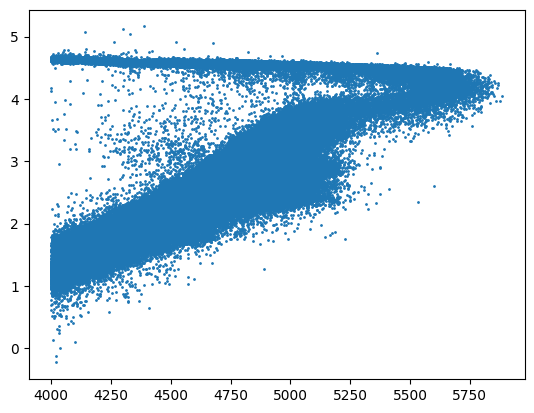

In [ ]:
plt.scatter(MST_sample.TEFF, MST_sample.LOGG, s = 1)

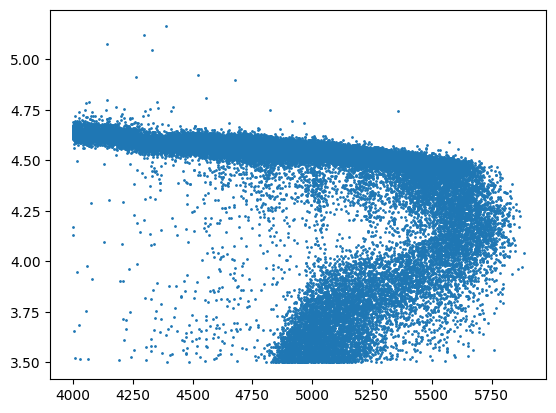

In [ ]:
plt.scatter(MST_sample[MST_sample.LOGG > 3.5].TEFF, MST_sample[MST_sample.LOGG > 3.5].LOGG, s = 1)

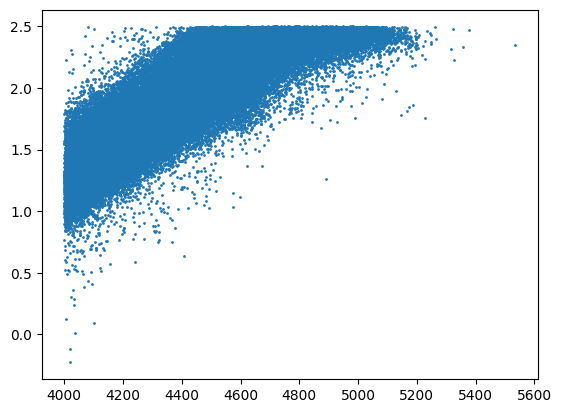

In [ ]:
plt.scatter(MST_sample[MST_sample.LOGG < 2.5].TEFF, MST_sample[MST_sample.LOGG < 2.5].LOGG, s = 1)

In [ ]:
MST_sample_dwarfs = MST_sample[(MST_sample['LOGG'] < 4.8) & (MST_sample['LOGG'] > 4.4) & (MST_sample['TEFF'] > 4500)]
print (f'{len(MST_sample_dwarfs)} dwarf stars')

24816 dwarf stars


In [ ]:
MST_sample_giants = MST_sample[(MST_sample['LOGG'] < 2.5) & (MST_sample['LOGG'] > 1)]
print (f'{len(MST_sample_giants)} giant stars')

83766 giant stars


In [ ]:
MST_final_sample = pd.merge(MST_sample_dwarfs, MST_sample_giants, how='outer')
print (f'{len(MST_final_sample)} total stars')

108582 total stars


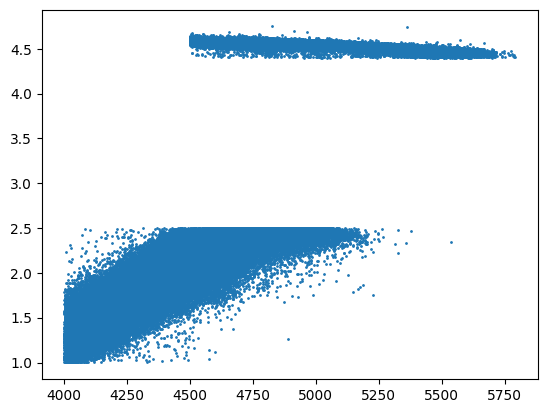

In [ ]:
plt.scatter(MST_final_sample.TEFF, MST_final_sample.LOGG, s = 1)

In [ ]:
MST_final_sample.columns

Index(['RA', 'DEC', 'GLON', 'GLAT', 'SNR', 'VHELIO_AVG', 'VERR',
       'GAIAEDR3_SOURCE_ID', 'GAIAEDR3_PARALLAX', 'GAIAEDR3_PARALLAX_ERROR',
       'GAIAEDR3_PMRA', 'GAIAEDR3_PMRA_ERROR', 'GAIAEDR3_PMDEC',
       'GAIAEDR3_PMDEC_ERROR', 'GAIAEDR3_PHOT_G_MEAN_MAG',
       'GAIAEDR3_PHOT_BP_MEAN_MAG', 'GAIAEDR3_PHOT_RP_MEAN_MAG',
       'GAIAEDR3_DR2_RADIAL_VELOCITY', 'GAIAEDR3_DR2_RADIAL_VELOCITY_ERROR',
       'GAIAEDR3_R_MED_GEO', 'GAIAEDR3_R_MED_PHOTOGEO', 'TEFF', 'TEFF_ERR',
       'LOGG', 'LOGG_ERR', 'M_H', 'M_H_ERR', 'ALPHA_M', 'ALPHA_M_ERR',
       'VMICRO', 'VMACRO', 'VSINI', 'C_H', 'C_H_ERR', 'O_H', 'O_H_ERR', 'MG_H',
       'MG_H_ERR', 'SI_H', 'SI_H_ERR', 'FE_H', 'FE_H_ERR'],
      dtype='object')

In [ ]:
def calculate_uvw(row):
    UVW_lsr =  UVW(row['RA'], row['DEC'], row['GAIAEDR3_PMRA'], row['GAIAEDR3_PMDEC'], row['VHELIO_AVG'], row['GAIAEDR3_PARALLAX'])
    return UVW_lsr[0], UVW_lsr[1], UVW_lsr[2] 

# Apply the function to each row using apply with axis=1
MST_final_sample['U_lsr'], MST_final_sample['V_lsr'], MST_final_sample['W_lsr'] = zip(*MST_final_sample.apply(calculate_uvw, axis=1))

In [ ]:
# Define a function to apply gal_population to each row
def calculate_probabilities(row):
    probs =  gal_population(row['U_lsr'], row['V_lsr'], row['W_lsr'], char_vel='Mean')
    return probs[0]

# Apply the function to each row using apply with axis=1
MST_final_sample['P_gal'] = MST_final_sample.apply(calculate_probabilities, axis=1)

c:\Users\adbva\IA\Students\PhD\Barbara_soares\m_dwarfs\samples\GalVel_Pop.py:160: RuntimeWarning: invalid value encountered in double_scalars
  Prob[key] = np.round(100 * abs_p[i] / np.sum(abs_p), 1)


In [ ]:
# Removing unnesseery columns
MST_final_sample = MST_final_sample.drop(['SNR', 'M_H', 'M_H_ERR', 'ALPHA_M', 'ALPHA_M_ERR', 'VMICRO', 
                                          'VMACRO', 'VSINI', 'GAIAEDR3_DR2_RADIAL_VELOCITY', 'GAIAEDR3_DR2_RADIAL_VELOCITY_ERROR',],axis = 1)

### Rounding numbers to reduce the size of the resulting csv file

In [ ]:
def rounding_to_decimals(df, cols, dec):
    for col in cols:
        df[col] = df[col].apply(lambda x: round(x, dec))
    return df

# Example usage with a list of columns
columns_to_round_to_2_decimals = [
    'GAIAEDR3_PARALLAX', 'GAIAEDR3_PARALLAX_ERROR', 'GAIAEDR3_PMRA',
    'GAIAEDR3_PMRA_ERROR', 'GAIAEDR3_PMDEC', 'GAIAEDR3_PMDEC_ERROR',
    'GAIAEDR3_PHOT_G_MEAN_MAG', 'GAIAEDR3_PHOT_BP_MEAN_MAG',
    'GAIAEDR3_PHOT_RP_MEAN_MAG', 'GAIAEDR3_R_MED_GEO',
    'GAIAEDR3_R_MED_PHOTOGEO', 'VHELIO_AVG', 'VERR',
    'C_H', 'C_H_ERR', 'O_H', 'O_H_ERR', 'MG_H', 'MG_H_ERR', 'SI_H',
    'SI_H_ERR', 'FE_H', 'FE_H_ERR', 'U_lsr', 'V_lsr', 'W_lsr',
    'LOGG', 'LOGG_ERR',
    ]

columns_to_round_to_0_decimals = ['TEFF', 'TEFF_ERR',]

MST_final_sample = rounding_to_decimals(MST_final_sample, columns_to_round_to_2_decimals, 2)
MST_final_sample = rounding_to_decimals(MST_final_sample, columns_to_round_to_0_decimals, 0)


In [ ]:
MST_final_sample.to_csv('apogeeDR17_MST_final_sample.csv')